# 08 · La popularité par pays

Questions de ce notebook :
1. quel est le Pokémon le plus populaire dans chaque pays ? (et est-ce qu'on retrouve l'étude de TheToyZone ?)
2. est-ce qu'on peut faire des groupes de pays qui ont les mêmes goûts ? (clustering du TP2, MDS et t-SNE du TP4)
3. est-ce que les pays voisins aiment les mêmes Pokémon ? (autocorrélation spatiale : Moran et LISA)

La seule source par pays, c'est **Google Trends** : les recherches sur les noms anglais, ramenées sur l'échelle de Gengar puis transformées en percentiles par pays dans le notebook 02 (on y a gardé les 67 pays qui ont assez de recherches). Ça mesure l'**attention** (ce que les gens cherchent), pas forcément l'affection. Les 28 Pokémon dont le nom anglais est aussi un mot courant (Persian, Durant, Onix…) ont été retirés de Google Trends dans le notebook 02 : ils n'apparaissent donc pas ici (on y revient dans la partie 4).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import pycountry

pd.set_option("display.max_columns", 50)
RAW = Path("../data/raw")
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
ratio = pd.read_csv(OUT / "trends_ratio_gengar_pays.csv", index_col="dex")
pct = pd.read_csv(OUT / "trends_percentile_pays.csv", index_col="dex")
ttz = pd.read_csv(RAW / "thetoyzone/favori_par_pays_et_generation.csv")
nom = table["nom_fr"]
print(ratio.shape, pct.shape, ttz.shape)

(997, 171) (997, 67) (853, 3)


## 1. Le Pokémon le plus cherché dans chaque pays

Dans chaque pays, le ratio à Gengar dit combien un Pokémon est cherché par rapport à Gengar. Le plus cherché, c'est celui qui a le plus grand ratio.

In [2]:
plus_cherche = ratio.idxmax()
plus_cherche.map(nom).value_counts().head(10)

Pikachu       145
Arceus         21
Luxio           2
Grotadmorv      1
Raichu          1
Kadabra         1
Name: count, dtype: int64

Sans surprise, **Pikachu est le plus cherché dans 145 pays sur 171**. Derrière, il n'y a presque qu'Arceus (21 pays), puis Luxio (2 pays) et quelques cas isolés (Grotadmorv, Raichu, Kadabra). Le « plus cherché » dit donc surtout « Pikachu, ou parfois Arceus » : ça ne permet pas de distinguer les pays.

### Ce qu'on a fait et pourquoi

**1. Le plus cherché = le plus grand ratio à Gengar.** Dans chaque pays, on prend le Pokémon qui a le plus grand ratio (un simple `idxmax`). On part du ratio et pas du percentile, parce que le percentile écrase le haut du classement (le premier est à 1 dans tous les pays, on ne voit pas de combien il domine), alors que le ratio garde l'écart.

**2. Un tableau de comptage plutôt qu'une carte.** Pour voir si ça distingue les pays, il suffit de compter combien de pays ont chaque favori. Comme c'est presque toujours le même Pokémon, une carte aurait été d'une seule couleur : le comptage montre directement que cette définition ne sert pas à comparer les pays, et c'est ce qui nous a poussés à chercher une autre définition juste après.

## 2. Le Pokémon « surreprésenté » (comme TheToyZone)

Comme le plus cherché c'est presque toujours le même, TheToyZone a pris une autre définition : le Pokémon dont **la part dans les recherches du pays dépasse le plus sa part dans le monde**.

- part dans le pays = ratio du Pokémon / somme des ratios de tous les Pokémon du pays ;
- part dans le monde : on n'a pas les volumes de recherche de chaque pays (Google Trends ne donne que du relatif), donc on prend **la moyenne des parts sur les pays** (chaque pays compte pareil) ;
- surreprésentation = part dans le pays / part dans le monde.

In [3]:
part = ratio / ratio.sum()
part_monde = part.mean(axis=1)
surrep = part.div(part_monde, axis=0)
surrep.stack().describe()

count    170436.000000
mean          1.000000
std           2.464415
min           0.000000
25%           0.000000
50%           0.541957
75%           1.603699
max         170.090267
dtype: float64

La surreprésentation vaut 1 en moyenne (normal, par construction). La médiane est à 0,54 parce que beaucoup de cases sont à 0 (0,15 avec la première collecte, qui avait encore plus de 0), et le maximum monte à 170.

In [4]:
fav_surrep = surrep.idxmax()
print("nombre de Pokémon différents :", fav_surrep.nunique())
fav_surrep.map(nom).value_counts().head(10)

nombre de Pokémon différents : 142


Flotoutan     5
Flabébé       4
Boguérisse    4
Hydragla      4
M. Mime       3
Nidoran♂      3
Feuillajou    2
Voltoutou     2
Virovent      2
Dinglu        2
Name: count, dtype: int64

Avec cette définition brute, on obtient 142 favoris différents, et les premiers sont des Pokémon peu connus (Flotoutan, Flabébé, Boguérisse, Hydragla…).

In [5]:
# le problème des petites valeurs : un Pokémon presque jamais cherché dans le monde mais un peu dans un pays a un énorme rapport
top = pd.DataFrame({"favori": fav_surrep.map(nom), "surrep": surrep.max(),
                    "part_monde_du_favori": part_monde[fav_surrep].values,
                    "pays_garde_notebook02": surrep.columns.isin(pct.columns)})
top.sort_values("surrep", ascending=False).head(10)

,favori,surrep,part_monde_du_favori,pays_garde_notebook02
Bermuda,Nidoran♀,170.090267,0.000089,False
Caribbean Netherlands,Dolman,147.619976,0.000607,False
Sint Maarten,Grotichon,145.810209,0.000396,False
Liberia,Miamiasme,145.359660,0.000936,False
St. Lucia,Piclairon,140.085899,0.000104,False
St. Kitts & Nevis,Polagriffe,131.276415,0.000341,False
Liechtenstein,Rongourmand,124.742194,0.000298,False
Antigua & Barbuda,Groret,113.145184,0.000192,False
Botswana,Neitram,111.101111,0.000118,False
Albania,Coxyclaque,106.391562,0.000603,False


Les plus grosses surreprésentations approchent 171, le nombre de pays : ce sont des Pokémon qui ne sont cherchés que dans **un seul** pays, ou presque (Nidoran♀ aux Bermudes à 170, Dolman aux Pays-Bas caribéens, Grotichon à Saint-Martin). Leur part dans le monde est minuscule (de l'ordre de 10⁻⁴), donc le moindre point de recherche les fait exploser. Les 10 plus grosses sont toutes dans des petits pays qu'on n'a pas gardés au notebook 02.

In [6]:
top.groupby("pays_garde_notebook02")["surrep"].describe()

,count,mean,std,min,25%,50%,75%,max
pays_garde_notebook02,,,,,,,,
False,104.0,48.764864,39.457607,5.704066,15.774804,36.974639,71.603492,170.090267
True,67.0,11.723604,11.700437,4.681594,5.608307,7.421816,11.447762,62.698487


C'est bien pire dans les 104 petits pays écartés au notebook 02 (médiane 37) que dans les 67 pays gardés (médiane 7,4).

### Ce qu'on a fait et pourquoi

**1. La surreprésentation, comme TheToyZone.** On ne regarde plus « qui est le plus cherché » mais « qui est plus cherché ici qu'ailleurs » : part du Pokémon dans le pays ÷ sa part dans le monde. On a pris cette définition parce que c'est celle de l'étude TheToyZone, à laquelle on veut se comparer, et parce qu'elle enlève l'effet « Pikachu partout » : un Pokémon cherché partout pareil a une surreprésentation de 1 dans tous les pays.

**2. La part dans le monde = la moyenne des parts des pays.** TheToyZone pondère par le volume de recherche de chaque pays, mais Google Trends ne donne que du relatif, donc on n'a pas ces volumes. Du coup chaque pays compte pareil. Ce n'est pas un choix « meilleur », c'est le seul possible avec nos données.

**3. Regarder les cas extrêmes avant de conclure.** Avant de faire une carte, on a trié les plus grosses surreprésentations et comparé les petits pays aux pays gardés au notebook 02 (un `describe` par groupe). C'est comme ça qu'on a vu que les maxima étaient des Pokémon cherchés dans un seul pays : une division par un tout petit nombre, donc du bruit et pas une préférence.

## 3. Comparaison avec TheToyZone

TheToyZone donne un favori par pays **et par génération** (pas de favori toutes générations). Pour comparer, on refait le même calcul à l'intérieur de chaque génération : on compare un Pokémon seulement aux Pokémon de sa génération.

In [7]:
print("pays TheToyZone :", ttz.pays.nunique())
manquants = sorted(set(ttz.pays) - set(ratio.columns))
print("pays TheToyZone absents de Google Trends (ou écrits autrement) :", manquants)

pays TheToyZone : 114
pays TheToyZone absents de Google Trends (ou écrits autrement) : ['Bosnia and Herzegovina', 'Cote d\\u2019Ivoire (Ivory Coast)', 'Czech Republic', 'Ireland (Republic of)', 'Macedonia (North)', 'Myanmar', 'Trinidad and Tobago', 'Turkey', 'United States of America']


9 pays de TheToyZone ne sont pas trouvés tels quels, mais ce sont presque tous des différences d'écriture (Czech Republic / Czechia, Turkey / Türkiye…).

In [8]:
nom_en_vers_dex = pd.Series(table.index, index=table["nom_en"].str.lower())
ttz["dex"] = ttz["pokemon"].str.lower().map(nom_en_vers_dex)
print("noms TheToyZone non reconnus :", ttz.loc[ttz.dex.isna(), "pokemon"].unique())

noms TheToyZone non reconnus : <StringArray>
['Sirfetch'd', 'Farfetch'd']
Length: 2, dtype: str


Côté Pokémon, seuls Farfetch'd et Sirfetch'd posent problème, à cause de l'apostrophe (droite chez TheToyZone, courbe dans PokéAPI).

In [9]:
# les noms de pays Google qui ressemblent à ceux qui manquent
[p for p in ratio.columns if any(m in p for m in ["Bosnia", "Ivoire", "Czech", "Ireland", "Macedonia", "Myanmar", "Trinidad", "Türk", "United States"])]

['Bosnia & Herzegovina',
 'Czechia',
 'Côte d’Ivoire',
 'Ireland',
 'Myanmar (Burma)',
 'North Macedonia',
 'Trinidad & Tobago',
 'Türkiye',
 'United States']

In [10]:
corr_pays = {"Bosnia and Herzegovina": "Bosnia & Herzegovina", "Cote d\\u2019Ivoire (Ivory Coast)": "Côte d’Ivoire",
             "Czech Republic": "Czechia", "Ireland (Republic of)": "Ireland", "Macedonia (North)": "North Macedonia",
             "Trinidad and Tobago": "Trinidad & Tobago", "Turkey": "Türkiye", "United States of America": "United States"}
ttz["pays_gt"] = ttz["pays"].replace(corr_pays)
ttz["dex"] = ttz["pokemon"].str.replace("'", "’").str.lower().map(nom_en_vers_dex)
print("pays encore absents :", sorted(set(ttz.pays_gt) - set(ratio.columns)))
print("noms non reconnus :", ttz.loc[ttz.dex.isna(), "pokemon"].unique())

pays encore absents : ['Myanmar']
noms non reconnus : <StringArray>
[]
Length: 0, dtype: str


Après correction, il ne reste que le Myanmar, qui n'est pas dans nos 171 pays sous ce nom (*Myanmar (Burma)*) et qui ne fait de toute façon pas partie des 67 pays gardés.

On a vu juste avant que la surreprésentation brute est dominée par les **Pokémon presque jamais cherchés** : si un Pokémon n'a une valeur que dans un seul pays, sa part dans ce pays divisée par sa part moyenne vaut à peu près le nombre de pays (171), le maximum possible. C'est du bruit des petites valeurs entières, pas une préférence.

Du coup on ajoute deux filtres :
- on ne garde que les **67 pays** fiables du notebook 02, parce que c'est dans les petits pays que le bruit est le pire (médiane 37 contre 7,4) ;
- un Pokémon ne peut être « favori » que s'il est cherché (ratio > 0) dans **au moins la moitié** de ces pays. On prend 50 % parce que c'est assez pour écarter les Pokémon fantômes qui n'existent que dans un pays, sans retirer les Pokémon peu connus mais cherchés un peu partout.

Pour la part dans le monde, on garde la moyenne des parts des pays (chaque pays compte pareil). On n'a pas le choix : Google Trends ne donne pas les volumes de recherche, donc on ne peut pas pondérer par la taille des pays comme TheToyZone.

In [11]:
MIN_PART_PAYS = 0.5   # le Pokémon doit avoir une valeur dans au moins 50 % des pays gardés

pays_ok = list(pct.columns)
r67 = ratio[pays_ok]
presence = (r67 > 0).mean(axis=1)
print("Pokémon qui passent le filtre :", (presence >= MIN_PART_PAYS).sum(), "sur", len(r67))

def favori_surrep(r, eligibles):
    p = r / r.sum()
    s = p.div(p.mean(axis=1), axis=0)
    return s.loc[eligibles].idxmax(), s.loc[eligibles].max()

eligibles = presence[presence >= MIN_PART_PAYS].index
fav67, val67 = favori_surrep(r67, eligibles)
print("nombre de favoris différents :", fav67.nunique())
fav67.map(nom).value_counts().head(10)

Pokémon qui passent le filtre : 995 sur 997
nombre de favoris différents : 52


Luxio           3
Pichu           3
Flabébé         3
Grotadmorv      3
Roue-de-Fer     2
Virevorreur     2
Pandespiègle    2
Frissonille     2
Tauros          2
Chongjian       2
Name: count, dtype: int64

Le filtre « cherché dans au moins 50 % des pays » ne retire plus que 2 Pokémon sur 997 (37 avec la première collecte : la deuxième collecte a donné une valeur à presque tous les Pokémon du bas). On a 52 favoris différents. Luxio, Pichu, Flabébé et Grotadmorv arrivent en tête (3 pays chacun), puis une série de Pokémon à 2 pays (Roue-de-Fer, Virevorreur, Pandespiègle, Tauros…). Il n'y a donc pas de favori qui domine : chaque pays a presque le sien.

In [12]:
pd.DataFrame({"favori": fav67.map(nom), "surrep": val67.round(1)}).sort_values("surrep", ascending=False).head(15)

,favori,surrep
France,Otarlette,43.4
Bangladesh,Pandespiègle,27.9
Ireland,Lombre,26.4
Türkiye,Celebi,22.4
Russia,Luxio,21.3
Indonesia,Luxio,18.8
Japan,Coxyclaque,17.3
Poland,Charmillon,16.5
India,Pandespiègle,15.9
Serbia,Frissonille,13.6


Les plus fortes surreprésentations restent des cas bizarres : Otarlette en France (×43), Pandespiègle au Bangladesh (×28), Lombre en Irlande (×26), Celebi en Turquie (×22), Luxio en Russie (×21).

### Comparaison par génération

Même calcul, mais à l'intérieur de chaque génération (on ne compare un Pokémon qu'aux Pokémon de sa génération), sur les pays qu'on a en commun avec TheToyZone.

In [13]:
lignes = []
for g in range(1, 10):
    dex_g = r67.index[table.loc[r67.index, "generation"] == g]
    rg = r67.loc[dex_g]
    elig_g = [d for d in dex_g if presence[d] >= MIN_PART_PAYS]
    fav_g, _ = favori_surrep(rg, elig_g)
    elig_tous = list(dex_g)
    fav_g_sans_filtre, _ = favori_surrep(rg[rg.sum(axis=1) > 0], [d for d in dex_g if rg.loc[d].sum() > 0])
    t = ttz[(ttz.generation == g) & ttz.pays_gt.isin(pays_ok)].set_index("pays_gt")["dex"]
    commun = t.index
    lignes.append({"generation": g, "pays_communs": len(commun),
                   "accord_avec_filtre": (fav_g[commun].values == t.values).mean(),
                   "accord_sans_filtre": (fav_g_sans_filtre[commun].values == t.values).mean()})
accord = pd.DataFrame(lignes).set_index("generation")
accord.round(2)

,pays_communs,accord_avec_filtre,accord_sans_filtre
generation,,,
1,65,0.23,0.20
2,65,0.22,0.22
3,65,0.17,0.17
4,65,0.12,0.12
5,65,0.09,0.09
6,65,0.28,0.28
7,65,0.15,0.15
8,65,0.08,0.08
9,54,0.09,0.09


**L'accord avec TheToyZone est faible** : 16 % des pays en moyenne (23 % en génération 1, 22 % en génération 2, 28 % en génération 6, mais 8 à 12 % pour les générations 4, 5, 8 et 9). C'est un peu mieux qu'avec la première collecte (11 %) : les Pokémon peu cherchés ne sont plus tous à 0, donc on retrouve plus souvent les mêmes favoris. Avec ou sans le filtre, ça donne maintenant la même chose, puisqu'il ne retire presque plus personne.

In [14]:
print("accord moyen (avec filtre) :", round(accord.accord_avec_filtre.mean(), 2), "| sans filtre :", round(accord.accord_sans_filtre.mean(), 2))
# combien de favoris différents chez TheToyZone, par génération ?
ttz.groupby("generation")["dex"].nunique()

accord moyen (avec filtre) : 0.16 | sans filtre : 0.16


generation
1    49
2    40
3    57
4    49
5    67
6    41
7    42
8    34
9    26
Name: dex, dtype: int64

TheToyZone a lui-même beaucoup de favoris différents (de 26 à 67 selon la génération), donc il n'y a pas un favori évident par génération qu'on aurait raté.

In [15]:
# exemple : la génération 1, nos favoris et ceux de TheToyZone côte à côte
g = 1
dex_g = r67.index[table.loc[r67.index, "generation"] == g]
fav_g1, _ = favori_surrep(r67.loc[dex_g], [d for d in dex_g if presence[d] >= MIN_PART_PAYS])
t = ttz[(ttz.generation == g) & ttz.pays_gt.isin(pays_ok)].set_index("pays_gt")["dex"]
comp = pd.DataFrame({"nous": fav_g1[t.index].map(nom), "TheToyZone": t.map(nom)})
comp.head(20)

,nous,TheToyZone
Argentina,Aquali,Aquali
Australia,Krabby,Grotadmorv
Austria,Grotadmorv,Grotadmorv
Bangladesh,Nosferalto,Grotadmorv
Belgium,Poissoroy,Doduo
Bolivia,M. Mime,Abra
Brazil,Saquedeneu,Roucoups
Bulgaria,Kadabra,Grotadmorv
Canada,Krabby,Flagadoss
Chile,Chrysacier,Aquali


Quand on compare pays par pays en génération 1, on retrouve parfois le même favori (Aquali en Argentine, Ronflex en Croatie, Grotadmorv en Autriche et en Tchéquie, Tadmorv au Danemark, Scarabrute en République dominicaine), 15 pays sur 65 en tout (10 avec la première collecte). Ailleurs, TheToyZone donne souvent Abra, qu'on a retiré (c'est aussi un mot courant, voir la partie 4), donc on ne peut pas le retrouver. Les écarts viennent aussi de la méthode : TheToyZone a des volumes de recherche absolus (outil Ahrefs) alors que nous n'avons que du relatif avec des petits entiers.

### Ce qu'on a fait et pourquoi

**1. Harmoniser avant de comparer.** Pour comparer avec TheToyZone, il faut que les noms de pays et de Pokémon soient écrits pareil des deux côtés. On a listé ceux qui ne se retrouvaient pas, puis corrigé à la main (Czech Republic → Czechia, apostrophe droite → courbe…). On a fait ça à la main plutôt qu'avec une recherche approchée parce qu'il n'y en avait que quelques-uns, et qu'une recherche approchée peut se tromper sans qu'on le voie.

**2. Deux filtres contre le bruit des petites valeurs.** On garde seulement les pays fiables du notebook 02, et un Pokémon ne peut être favori que s'il est cherché dans au moins la moitié de ces pays. Le seuil de 50 % est un compromis : assez haut pour écarter les Pokémon « fantômes » qui n'existent que dans un pays, assez bas pour garder les Pokémon peu connus mais cherchés un peu partout.

**3. Comparer génération par génération.** TheToyZone ne donne un favori que par génération, donc on refait le même calcul à l'intérieur de chaque génération pour comparer la même chose. On mesure l'accord comme la part des pays où on trouve le même favori : c'est simple et ça se lit directement. On le calcule avec et sans le filtre, pour vérifier que le filtre ne nous éloigne pas de TheToyZone.

**4. Le tableau côte à côte.** Pour la génération 1, on met nos favoris et ceux de TheToyZone l'un à côté de l'autre, pays par pays. Un pourcentage d'accord tout seul ne dit pas pourquoi on n'est pas d'accord ; le tableau permet de voir les cas (par exemple les Pokémon qu'on a retirés et qu'on ne peut donc jamais retrouver).

## 4. Les noms ambigus retirés

Dans le notebook 02, on a repéré 28 Pokémon dont le nom anglais est aussi un mot courant, un prénom ou une marque (Persian, Durant, Ditto, Onix, Abra…). Pour eux, Google compte aussi les recherches sur le mot, pas seulement sur le Pokémon : avant de les retirer, Persian sortait « le plus cherché » dans 15 pays, et Onix faisait ressortir l'Amérique du Sud à cause de la voiture Chevrolet Onix. Comme on ne veut mesurer que des Pokémon et pas des mots, on les a enlevés de Google Trends dès le notebook 02. On vérifie ici qu'ils ne sont plus là et ce que ça donne sur les 67 pays gardés.

In [16]:
pop = pd.read_csv(OUT / "popularite_sources.csv", index_col="dex")
dex_retires = pop.index[pop["trends_nom_ambigu"]]
print(len(dex_retires), "Pokémon retirés :", ", ".join(nom[dex_retires]))
print("encore présents dans Google Trends :", ratio.index.isin(dex_retires).sum())
print("pays (sur 67) où Pikachu est le plus cherché :", (r67.idxmax() == 25).sum())
print(r67.idxmax().map(nom).value_counts())
print("favoris surreprésentés différents :", fav67.nunique())
# TheToyZone, lui, les a gardés : combien de ses favoris (pays gardés) sont des Pokémon retirés ?
t = ttz[ttz.pays_gt.isin(pays_ok)]
print("favoris TheToyZone retirés chez nous :", t.dex.isin(dex_retires).sum(), "sur", len(t))
print(t.loc[t.dex.isin(dex_retires), "dex"].map(nom).value_counts().to_dict())

28 Pokémon retirés : Ortide, Paras, Persian, Abra, Grolem, Otaria, Fantominus, Onix, Hypnomade, Électrode, Lippoutou, Métamorph, Kabuto, Mew, Natu, Yanma, Galekid, Négapi, Muciole, Ratentif, Munna, Mascaïman, Tic, Clic, Fermite, Paume-de-Fer, Vert-de-Fer, Chef-de-Fer
encore présents dans Google Trends : 0
pays (sur 67) où Pikachu est le plus cherché : 62
Pikachu    62
Arceus      4
Luxio       1
Name: count, dtype: int64
favoris surreprésentés différents : 52
favoris TheToyZone retirés chez nous : 25 sur 574
{'Abra': 8, 'Natu': 6, 'Négapi': 3, 'Yanma': 2, 'Ortide': 2, 'Hypnomade': 2, 'Kabuto': 1, 'Lippoutou': 1}


Les 28 Pokémon ne sont plus dans les données. Sur les 67 pays gardés, **Pikachu est le plus cherché dans 62 pays**, Arceus dans 4 (Thaïlande, Philippines, Arabie saoudite, Ukraine) et Luxio en Russie. Pour le favori surreprésenté, on a 52 favoris différents, sans aucun mot courant au milieu. Le seul prix à payer, c'est pour la comparaison avec TheToyZone : 25 de ses 574 favoris (dans nos pays) sont des Pokémon qu'on a retirés (Abra dans 8 pays, Natu dans 6…), on ne peut donc jamais les retrouver. On accepte cette perte, parce que ces favoris-là viennent sans doute en partie des recherches sur le mot.

## 5. La carte

Il faut passer des noms de pays de Google aux codes ISO à 3 lettres (ce que demandent plotly et les contours de pays). On utilise `pycountry`, et on vérifie ceux qu'il ne trouve pas.

In [17]:
def iso3(p):
    try:
        return pycountry.countries.lookup(p).alpha_3
    except LookupError:
        try:
            return pycountry.countries.search_fuzzy(p)[0].alpha_3
        except LookupError:
            return None

codes = pd.Series({p: iso3(p) for p in ratio.columns})
print("pays sans code :", codes[codes.isna()].index.tolist())
# on vérifie à l'œil les pays dont le nom Google ne correspond pas exactement au nom pycountry
verif = pd.DataFrame({"code": codes.dropna(), "nom_pycountry": [pycountry.countries.get(alpha_3=c).name for c in codes.dropna()]})
verif[verif.index != verif.nom_pycountry]

pays sans code : ['Antigua & Barbuda', 'Bosnia & Herzegovina', 'Cape Verde', 'Caribbean Netherlands', 'Côte d’Ivoire', 'Myanmar (Burma)', 'St. Helena', 'St. Kitts & Nevis', 'St. Lucia', 'Trinidad & Tobago', 'U.S. Virgin Islands']


,code,nom_pycountry
Bolivia,BOL,"Bolivia, Plurinational State of"
Brunei,BRN,Brunei Darussalam
Iran,IRN,"Iran, Islamic Republic of"
Kosovo,SRB,Serbia
Laos,LAO,Lao People's Democratic Republic
Moldova,MDA,"Moldova, Republic of"
Palestine,PSE,"Palestine, State of"
Russia,RUS,Russian Federation
Sint Maarten,NLD,Netherlands
South Korea,KOR,"Korea, Republic of"


In [18]:
# corrections à la main : les pays non trouvés, et deux erreurs de la recherche approchée (Kosovo → Serbie, Sint Maarten → Pays-Bas)
codes = codes.copy()
codes.update(pd.Series({"Antigua & Barbuda": "ATG", "Bosnia & Herzegovina": "BIH", "Cape Verde": "CPV", "Caribbean Netherlands": "BES",
                        "Côte d’Ivoire": "CIV", "Myanmar (Burma)": "MMR", "St. Helena": "SHN", "St. Kitts & Nevis": "KNA",
                        "St. Lucia": "LCA", "Trinidad & Tobago": "TTO", "U.S. Virgin Islands": "VIR",
                        "Kosovo": "XKX", "Sint Maarten": "SXM"}))
print("pays sans code :", codes[codes.isna()].index.tolist())
print("codes en double :", codes[codes.duplicated(keep=False)].to_dict())

pays sans code : []
codes en double : {}


Tous les pays ont maintenant un code ISO, sans doublon.

In [19]:
fav_s, val_s = favori_surrep(r67, eligibles)
plus_ch = r67.idxmax()
carte = pd.DataFrame({"pays": pays_ok, "iso3": codes[pays_ok].values,
                      "plus_cherche": plus_ch.map(nom).values,
                      "favori_surrep": fav_s.map(nom).values,
                      "surrep": val_s.round(1).values})
carte["generation_favori"] = table.loc[fav_s.values, "generation"].values
fig = px.choropleth(carte, locations="iso3", color="generation_favori", hover_name="pays",
                    hover_data=["favori_surrep", "surrep", "plus_cherche"], color_continuous_scale="viridis",
                    title="Pokémon surreprésenté dans chaque pays (couleur = sa génération)")
fig.show()
carte.sort_values("pays").head(67)

,pays,iso3,plus_cherche,favori_surrep,surrep,generation_favori
3,Argentina,ARG,Pikachu,Pichu,3.2,2
5,Australia,AUS,Pikachu,Roue-de-Fer,2.6,9
42,Austria,AUT,Pikachu,Séléroc,4.9,3
58,Bangladesh,BGD,Pikachu,Pandespiègle,27.9,6
7,Belgium,BEL,Pikachu,Flabébé,4.3,6
...,...,...,...,...,...,...
24,United Kingdom,GBR,Pikachu,Sorboul,2.3,5
25,United States,USA,Pikachu,Krabby,3.2,1
48,Uruguay,URY,Pikachu,Pichu,3.0,2
26,Venezuela,VEN,Pikachu,Pomdepik,5.8,2


In [20]:
carte["generation_favori"].value_counts().sort_index()

generation_favori
1    12
2    10
3     8
4     6
5     4
6     7
7     4
8     6
9    10
Name: count, dtype: int64

Les favoris surreprésentés viennent de toutes les générations. La génération 1 arrive en tête (12 pays), puis les générations 2 et 9 (10 pays chacune). Avec la première collecte, c'était la génération 9 en tête (13 pays) et la génération 1 n'avait que 8 pays : les Pokémon peu cherchés de la génération 1 étaient écrasés à 0 dans les lots avec des stars (voir la partie 4 du notebook 02), ils ont maintenant une valeur et peuvent ressortir. Ça reste très réparti, et ce sont surtout des Pokémon de niche propres à chaque pays (Pichu, Krabby…), plus qu'une vraie nostalgie.

### Ce qu'on a fait et pourquoi

**1. Vérifier le retrait des noms ambigus.** Dans la partie 4, on vérifie juste que les 28 Pokémon ne sont plus là et on regarde ce que ça change sur les favoris. C'est une vérification, pas une nouvelle méthode, mais c'était important de la faire ici parce que ces noms changeaient beaucoup les résultats par pays.

**2. Les codes pays avec `pycountry`, puis à la main.** Pour faire une carte, il faut le code ISO à 3 lettres de chaque pays. On a utilisé `pycountry` pour aller vite, mais on a vérifié tous les pays qui ne tombaient pas exactement sur le même nom, parce que la recherche approchée s'était trompée (Kosovo → Serbie, Sint Maarten → Pays-Bas). On a ensuite vérifié qu'il n'y avait ni pays sans code, ni code en double.

**3. Une carte choroplèthe colorée par génération du favori.** On a choisi une carte parce que la question est géographique : on veut voir si des régions entières ont des favoris du même genre. On colore par la génération du favori plutôt que par le favori lui-même, parce qu'avec des dizaines de favoris différents on aurait des dizaines de couleurs illisibles ; la génération résume en une couleur et permet de voir s'il y a une nostalgie par région. Le nom du favori reste visible au survol (la carte est interactive avec plotly).

## 6. Des groupes de pays qui ont les mêmes goûts ?

Dans le notebook 02, on a vu que les pays se ressemblent énormément (Spearman médian 0,91 entre deux pays) : tout le monde cherche à peu près les mêmes Pokémon. Si on fait le clustering sur les percentiles bruts, ce fond commun va tout écraser et on ne verra que des groupes « gros pays / petits pays ».

Du coup on **retire le fond commun** : pour chaque Pokémon, on enlève son percentile moyen sur les pays. Il reste, pour chaque pays, « ce Pokémon est plus (ou moins) cherché ici qu'en moyenne ». C'est le même esprit que la surreprésentation de TheToyZone, mais sur tous les Pokémon d'un coup.

On garde les 67 pays fiables et seulement les Pokémon cherchés dans au moins 50 % des pays (même filtre qu'avant, pour la même raison : les Pokémon presque jamais cherchés ne font que du bruit).

In [21]:
P = pct.loc[eligibles]                      # Pokémon × pays
# il reste quelques trous : les lots où Gengar n'avait pas de valeur dans un pays (notebook 02)
print("cases vides :", int(P.isna().sum().sum()), "dans", int((P.isna().sum() > 0).sum()), "pays")
X = P.sub(P.mean(axis=1), axis=0).T      # pays × Pokémon, fond commun retiré
X = X.fillna(0)                          # une case vide = « comme la moyenne des pays »
print(X.shape)
X.iloc[:5, :5]

cases vides : 0 dans 0 pays
(67, 995)


dex,1,2,3,4,5
Indonesia,-0.000741,0.019461,0.009761,-0.003975,0.007238
Malaysia,0.000763,0.012440,0.000734,0.000539,0.001220
Poland,0.009791,0.005419,0.005247,0.004551,-0.025861
Argentina,0.008286,0.044035,0.001235,0.008563,0.035824
Finland,0.008788,0.014446,0.022800,0.001542,-0.103093


Avec la deuxième collecte, il n'y a plus aucune case vide (avec la première, il y en avait 4 dans 2 pays : des lots où Gengar n'avait pas de valeur). On garde quand même la règle dans le code : une case vide serait remplie par 0, c'est-à-dire « comme la moyenne des pays », le choix le plus neutre. On a 67 pays décrits chacun par 995 Pokémon.

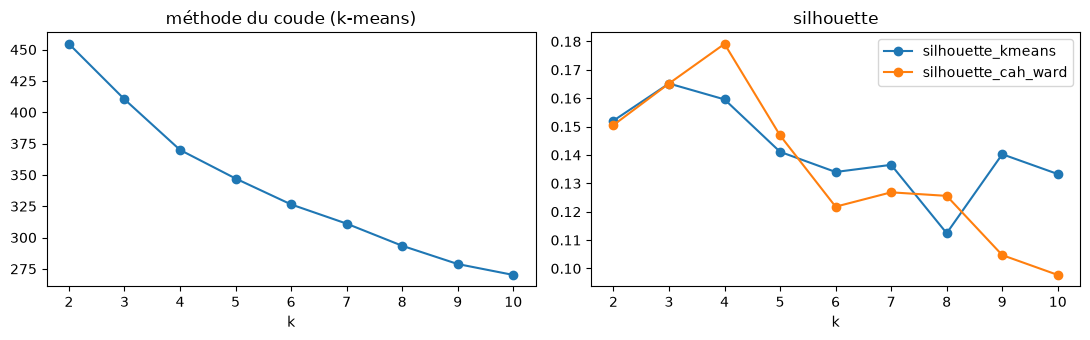

,inertie_kmeans,silhouette_kmeans,silhouette_cah_ward
k,,,
2,454.552,0.152,0.151
3,410.315,0.165,0.165
4,369.926,0.160,0.179
5,347.110,0.141,0.147
6,326.427,0.134,0.122
7,311.089,0.137,0.127
8,293.428,0.112,0.126
9,278.850,0.140,0.105
10,270.148,0.133,0.098


In [22]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    cah = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    scores.append({"k": k, "inertie_kmeans": km.inertia_, "silhouette_kmeans": silhouette_score(X, km.labels_),
                   "silhouette_cah_ward": silhouette_score(X, cah.labels_)})
scores = pd.DataFrame(scores).set_index("k")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
scores["inertie_kmeans"].plot(ax=axes[0], marker="o", title="méthode du coude (k-means)")
scores[["silhouette_kmeans", "silhouette_cah_ward"]].plot(ax=axes[1], marker="o", title="silhouette")
plt.tight_layout()
plt.show()
scores.round(3)

La silhouette est **faible partout** (entre 0,10 et 0,18). Le coude n'est pas net non plus. Les groupes de pays existent mais ils ne sont pas très séparés : c'est cohérent avec le notebook 02, où tous les pays se ressemblaient beaucoup.

k = 4 est le meilleur score de la CAH (0,179). Pour le k-means, k = 3 est très légèrement au-dessus (0,165 contre 0,160 pour k = 4), mais l'écart est minuscule. Avec la première collecte, k = 4 était le meilleur pour les deux méthodes. **On garde k = 4**, et on va voir que ça donne des groupes qui ont un sens.

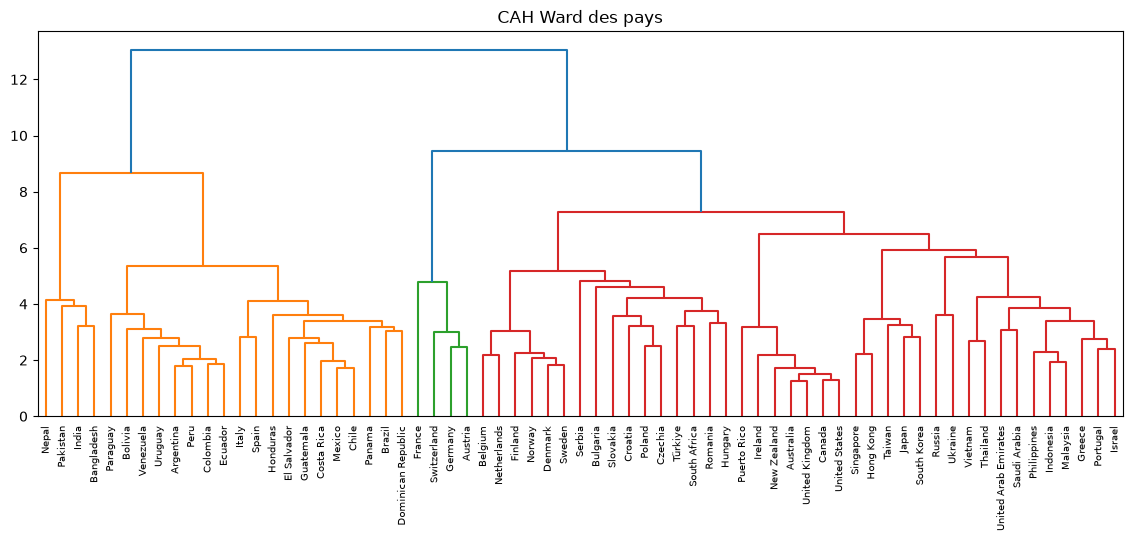

In [23]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, labels=X.index.tolist(), leaf_font_size=7, ax=ax)
ax.set_title("CAH Ward des pays")
plt.show()

In [24]:
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(X)
cah = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
groupes = pd.DataFrame({"kmeans": km.labels_, "cah": cah.labels_}, index=X.index)
print("silhouette k-means :", round(silhouette_score(X, km.labels_), 3), "| CAH :", round(silhouette_score(X, cah.labels_), 3))
pd.crosstab(groupes.kmeans, groupes.cah)

silhouette k-means : 0.16 | CAH : 0.179


cah,0,1,2,3
kmeans,,,,
0,14,0,0,4
1,0,19,0,0
2,26,0,0,0
3,0,0,4,0


Avec k = 4, k-means et CAH sont d'accord sur deux groupes : l'Amérique latine avec l'Espagne et l'Italie (exactement les mêmes 19 pays) et les 4 pays Allemagne, France, Suisse, Autriche. Par contre ils coupent autrement le reste : la CAH met l'Asie du Sud (Inde, Bangladesh, Pakistan, Népal) à part et laisse tout le reste ensemble, alors que le k-means coupe le reste du monde en deux (Europe de l'Est, Golfe et Asie du Sud-Est avec l'Asie du Sud d'un côté, Europe de l'Ouest, pays anglophones et Asie de l'Est de l'autre). On garde la **CAH Ward** pour la suite, parce que le dendrogramme permet de voir comment les groupes se forment et que ses groupes sont plus faciles à interpréter.

In [25]:
for g, d in groupes.groupby("cah"):
    print(f"groupe {g} ({len(d)} pays) :", ", ".join(d.index))

groupe 0 (40 pays) : Indonesia, Malaysia, Poland, Finland, Australia, Canada, Belgium, Netherlands, Japan, Denmark, Norway, Portugal, Philippines, Vietnam, Sweden, Thailand, Singapore, United Kingdom, United States, Ireland, New Zealand, South Korea, Czechia, Greece, Türkiye, South Africa, Hong Kong, Puerto Rico, Israel, United Arab Emirates, Taiwan, Russia, Romania, Hungary, Saudi Arabia, Croatia, Slovakia, Ukraine, Serbia, Bulgaria
groupe 1 (19 pays) : Argentina, Peru, Italy, Mexico, Colombia, Chile, Spain, Venezuela, Brazil, Costa Rica, Ecuador, Uruguay, Guatemala, Dominican Republic, Panama, El Salvador, Bolivia, Honduras, Paraguay
groupe 2 (4 pays) : Germany, France, Switzerland, Austria
groupe 3 (4 pays) : India, Pakistan, Bangladesh, Nepal


Les groupes de la CAH sont très **géographiques et linguistiques**, alors que le clustering ne connaît pas la position des pays :
- **groupe 0** (40 pays) : le « reste du monde », pays anglophones, Europe du Nord, de l'Ouest et de l'Est, Asie de l'Est et du Sud-Est, Golfe, Turquie ;
- **groupe 1** (19 pays) : toute l'**Amérique latine**, plus l'Espagne et l'Italie ;
- **groupe 2** (4 pays) : **Allemagne, France, Suisse, Autriche** (l'Allemagne, qui vient d'entrer dans les 67 pays, rejoint directement ce groupe) ;
- **groupe 3** (4 pays) : l'**Asie du Sud** (Inde, Bangladesh, Pakistan, Népal).

In [26]:
# ce qui distingue chaque groupe : les Pokémon les plus au-dessus de la moyenne dans le groupe
moy = X.groupby(groupes.cah).mean().T
for g in moy.columns:
    t = moy[g].sort_values(ascending=False).head(8)
    print(f"groupe {g} :", ", ".join(f"{nom[d]} (+{v:.2f})" for d, v in t.items()))

groupe 0 : Serpente-Eau (+0.14), Rugit-Lune (+0.12), Garde-de-Fer (+0.11), Hotte-de-Fer (+0.10), Fort-Ivoire (+0.09), Poissoroy (+0.09), Épine-de-Fer (+0.08), Hurle-Queue (+0.08)
groupe 1 : Germignon (+0.21), Nirondelle (+0.18), Gaulet (+0.15), Chrysacier (+0.14), Crocorible (+0.14), Venipatte (+0.13), Tritonde (+0.13), Poichigeon (+0.13)
groupe 2 : Hippopotas (+0.46), Luminéon (+0.44), Octillery (+0.42), Coxyclaque (+0.39), Rémoraid (+0.39), Snubbull (+0.38), Otarlette (+0.38), Yanmega (+0.37)
groupe 3 : Dodoala (+0.45), Hélédelle (+0.41), Hotte-de-Fer (+0.36), Massko (+0.32), Charmillon (+0.31), Pandespiègle (+0.31), Macronium (+0.31), Croâporal (+0.30)


Ce qui distingue chaque groupe :
- groupe 0 (reste du monde) : des Pokémon Paradoxe et légendaires récents (Serpente-Eau, Rugit-Lune, Garde-de-Fer, Hotte-de-Fer…), avec des écarts faibles (+0,08 à +0,14), ce qui est normal pour un groupe qui contient presque tous les pays ;
- groupe 1 (Amérique latine) : des Pokémon anciens et des formes de base (Germignon, Nirondelle, Gaulet, Chrysacier, Crocorible, Venipatte…) ;
- groupe 2 (Allemagne, France, Suisse, Autriche) : des Pokémon de génération 2 à 4 peu connus (Hippopotas, Luminéon, Octillery, Coxyclaque, Otarlette…), avec des écarts très forts (+0,37 à +0,46 de percentile) ;
- groupe 3 (Asie du Sud) : Dodoala, Hélédelle, Hotte-de-Fer, Massko, Charmillon, Pandespiègle… (+0,30 à +0,45).

Une piste pour le groupe Allemagne / France / Suisse / Autriche : dans ces pays, on cherche en français ou en allemand, et les noms anglais (ceux de notre collecte) sont moins tapés. Il reste alors peu de recherches, et les petites valeurs prennent beaucoup de place. Le fait que l'Allemagne rejoigne directement ce groupe va dans le sens de cette piste.

In [27]:
# la génération des Pokémon surreprésentés : est-ce qu'un groupe est plus « nostalgique » ?
gen = table.loc[X.columns, "generation"]
X.T.groupby(gen).mean().T.groupby(groupes.cah).mean().round(3)

generation,1,2,3,4,5,6,7,8,9
cah,,,,,,,,,
0,0.001,-0.006,-0.017,-0.001,-0.013,0.000,0.009,0.009,0.026
1,0.007,0.007,0.024,-0.003,0.025,0.003,-0.018,-0.015,-0.048
2,-0.050,0.051,0.024,0.023,-0.029,-0.019,-0.006,-0.014,0.031
3,0.006,-0.018,0.030,-0.003,0.035,-0.000,0.007,-0.007,-0.068


Par génération, l'Amérique latine (groupe 1) cherche moins la génération 9 (−0,05) et un peu plus les générations 3 et 5. Le reste du monde (groupe 0) cherche un peu plus la génération 9 (+0,03). Le groupe Allemagne / France / Suisse / Autriche (groupe 2) cherche moins la génération 1 (−0,05) et plus la génération 2 (+0,05). L'Asie du Sud (groupe 3) est celui qui cherche le moins la génération 9 (−0,07), et plus les générations 3 et 5.

### Ce qu'on a fait et pourquoi

**1. Retirer le fond commun avant de grouper.** Tous les pays cherchent à peu près les mêmes Pokémon. Si on groupe sur les percentiles bruts, ce fond commun écrase tout. Du coup on centre chaque Pokémon (on enlève son percentile moyen sur les pays) : il reste seulement « plus ou moins cherché ici qu'en moyenne », ce qui est justement ce qui distingue les pays.

**2. Les cases vides remplies par 0.** Après centrage, 0 veut dire « comme la moyenne des pays », c'est le choix le plus neutre possible. On ne supprime pas les pays concernés, parce qu'il n'y avait que quelques cases vides (et plus aucune depuis la deuxième collecte).

**3. Deux méthodes de clustering : k-means et CAH Ward (TP2).** On a fait les deux pour voir si les groupes tiennent quel que soit l'algorithme. Quand deux méthodes différentes trouvent les mêmes groupes, on peut y croire davantage. On a pris Ward pour la CAH parce qu'il cherche, comme le k-means, des groupes les plus homogènes possible, donc les deux sont comparables.

**4. Choisir k avec le coude et la silhouette.** Le coude (l'inertie du k-means) baisse toujours quand k augmente, donc on cherche la cassure ; la silhouette dit si chaque pays est mieux dans son groupe que dans le groupe d'à côté. On a regardé les deux parce que le coude n'était pas net. On a pris le k qui avait la meilleure silhouette pour la CAH et presque la meilleure pour le k-means, plutôt que le meilleur d'une seule méthode.

**5. Le dendrogramme et le tableau croisé.** Le dendrogramme montre comment les pays se regroupent petit à petit, ce que le k-means ne montre pas : c'est pour ça qu'on a gardé la CAH pour la suite. Le tableau croisé k-means × CAH montre exactement quels groupes les deux méthodes partagent et lesquels elles coupent différemment.

**6. Décrire les groupes par leurs Pokémon et leurs générations.** Un groupe n'a de sens que si on sait ce qu'il a de particulier. On a donc fait la moyenne du profil centré dans chaque groupe et regardé les Pokémon les plus au-dessus de la moyenne, puis la même chose par génération, pour voir si un groupe est plus « nostalgique ».

## 7. MDS et t-SNE des pays (TP4)

On place les pays sur une carte 2D où deux pays proches ont des goûts proches. La distance entre deux pays = 1 − corrélation de Spearman entre leurs profils (fond commun retiré).

Pour le t-SNE, on prend une **perplexité de 10** au lieu de 30 (la valeur par défaut) : la perplexité, c'est en gros le nombre de voisins que chaque point « regarde », et avec seulement 67 pays, 30 reviendrait à regarder presque la moitié des pays.

stress de Kruskal : 0.266


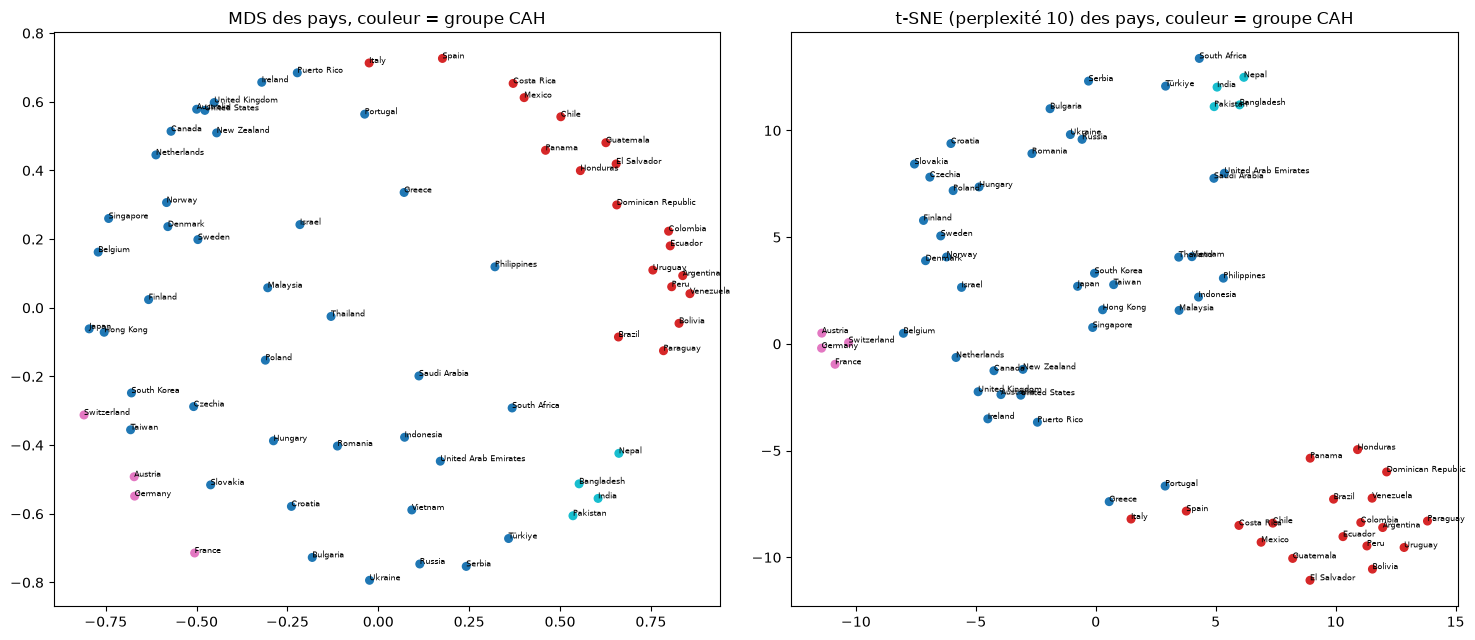

In [28]:
from sklearn.manifold import MDS, TSNE

D = 1 - X.T.corr(method="spearman")
mds = MDS(n_components=2, metric="precomputed", init="classical_mds", random_state=0)
coord_mds = pd.DataFrame(mds.fit_transform(D.values), index=X.index, columns=["mds1", "mds2"])
# stress de Kruskal (0 = distances parfaitement respectées ; au-dessus de 0,2 la carte déforme beaucoup)
d_2d = np.sqrt(((coord_mds.values[:, None, :] - coord_mds.values[None, :, :]) ** 2).sum(-1))
stress = np.sqrt(((D.values - d_2d) ** 2).sum() / (D.values ** 2).sum())
print("stress de Kruskal :", round(stress, 3))
tsne = TSNE(n_components=2, metric="precomputed", init="random", perplexity=10, random_state=0)
coord_tsne = pd.DataFrame(tsne.fit_transform(D.values), index=X.index, columns=["tsne1", "tsne2"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, cdf, titre in [(axes[0], coord_mds, "MDS"), (axes[1], coord_tsne, "t-SNE (perplexité 10)")]:
    ax.scatter(cdf.iloc[:, 0], cdf.iloc[:, 1], c=groupes.cah, cmap="tab10", s=30)
    for p, (a, b) in cdf.iterrows():
        ax.annotate(p, (a, b), fontsize=6)
    ax.set_title(titre + " des pays, couleur = groupe CAH")
plt.tight_layout()
plt.show()

Le **stress de Kruskal vaut 0,27** (0,29 avec la première collecte) : la carte 2D déforme pas mal les vraies distances entre pays (on considère souvent qu'au-dessus de 0,2, c'est médiocre). On garde quand même la MDS, mais on lit surtout son premier axe, et on ne tire pas de conclusion sur la distance exacte entre deux pays.

In [29]:
# MDS1 : de quoi il s'agit ? on regarde les Pokémon les plus liés à l'axe
lien = X.corrwith(coord_mds["mds1"], method="spearman")
print("côté positif :", ", ".join(nom[d] for d in lien.sort_values(ascending=False).head(10).index))
print("côté négatif :", ", ".join(nom[d] for d in lien.sort_values().head(10).index))
print("pays aux extrémités :", coord_mds.mds1.sort_values().index[:5].tolist(), "...", coord_mds.mds1.sort_values().index[-5:].tolist())

côté positif : Dynavolt, Roucool, Nirondelle, Draby, Arcko, Grainipiot, Kraknoix, Griknot, Crocorible, Poussifeu
côté négatif : Reshiram, Prismillon, Lestombaile, Rugit-Lune, Ampibidou, Zacian, Morpeko, Zekrom, Terraiste, Oyacata
pays aux extrémités : ['Switzerland', 'Japan', 'Belgium', 'Hong Kong', 'Singapore'] ... ['Ecuador', 'Peru', 'Bolivia', 'Argentina', 'Venezuela']


L'axe MDS 1 va de **Suisse, Japon, Belgique, Hong Kong, Singapour** d'un côté à **Équateur, Pérou, Bolivie, Argentine, Venezuela** de l'autre. Côté Amérique latine, on trouve des formes de base anciennes (Dynavolt, Roucool, Nirondelle, Draby, Arcko…). De l'autre côté, ce sont des légendaires et des Pokémon récents (Reshiram, Prismillon, Rugit-Lune, Zacian, Zekrom…).

In [30]:
carte["groupe"] = carte["pays"].map(groupes.cah).astype(str)
fig = px.choropleth(carte, locations="iso3", color="groupe", hover_name="pays", title="Groupes de pays (CAH Ward, k = 4)")
fig.show()

### Ce qu'on a fait et pourquoi

**1. Une distance 1 − Spearman entre pays.** Deux pays sont proches s'ils classent les Pokémon dans le même ordre. On prend Spearman et pas la distance euclidienne, parce qu'on travaille sur des percentiles (des rangs) et qu'on veut comparer l'ordre des goûts, pas l'écart exact des valeurs.

**2. MDS et t-SNE (TP4), les deux.** La MDS essaie de respecter toutes les distances, y compris entre pays très éloignés : ses axes peuvent donc s'interpréter. Le t-SNE ne cherche qu'à garder les voisins proches ensemble : il fait de jolis paquets mais les distances entre paquets ne veulent rien dire. On a fait les deux parce qu'ils répondent à deux questions différentes : « quel est le grand axe de différence ? » pour la MDS, « qui ressemble à qui ? » pour le t-SNE.

**3. La perplexité du t-SNE baissée.** La perplexité, c'est à peu près le nombre de voisins que chaque point regarde. La valeur par défaut (30) est faite pour des milliers de points ; avec seulement 67 pays, elle reviendrait à regarder presque la moitié des pays, donc on l'a baissée.

**4. Le stress de Kruskal pour juger la MDS.** Une carte en 2D déforme forcément les distances. Le stress mesure de combien : 0, c'est parfait, et au-dessus de 0,2 la carte est considérée comme médiocre. On l'a calculé pour savoir jusqu'où on pouvait faire confiance à la carte. Comme il est assez haut, on ne lit que le premier axe, et pas la distance exacte entre deux pays.

**5. Interpréter l'axe 1 avec les Pokémon qui lui sont liés.** Un axe de MDS n'a pas de nom tout seul. On a corrélé (Spearman) chaque Pokémon avec la coordonnée MDS 1 des pays, et regardé les Pokémon aux deux bouts et les pays aux deux extrémités : c'est ce qui permet de dire ce que l'axe oppose.

**6. Les nuages colorés par groupe CAH, et une carte des groupes.** On a mis la couleur des groupes de la partie 6 sur les nuages MDS / t-SNE pour vérifier que les groupes se retrouvent aussi quand on regarde les distances autrement. Puis on a mis les groupes sur une carte du monde, parce que c'est là qu'on voit tout de suite que les groupes suivent la géographie et la langue, alors que l'algorithme ne connaissait pas la position des pays.

## 8. Les pays voisins ont-ils les mêmes goûts ? (Moran et LISA)

L'**autocorrélation spatiale**, c'est la question : est-ce qu'une valeur dans un pays ressemble à la valeur dans les pays voisins ?
- l'**indice de Moran (I)** répond pour toute la carte d'un coup : I proche de 0 = pas de lien avec les voisins, I positif = les voisins se ressemblent ;
- le **LISA** (Moran local) répond pays par pays : il repère les pays qui ont une valeur haute entourés de voisins hauts (HH), basse entourés de bas (LL), ou les exceptions (HL, LH). La significativité est testée en mélangeant les valeurs au hasard entre pays (permutations).

**Les variables testées.** Il faut un seul nombre par pays. On en prend deux :
1. la **part des recherches qui vont aux Pokémon de la génération 1**, parce que c'est la façon la plus simple de mesurer la nostalgie pays par pays, et que la génération 1 est l'effet le plus fort trouvé dans le notebook 05 ;
2. la **coordonnée MDS 1** des pays, parce que c'est l'axe principal de différence de goûts trouvé juste avant : ça résume tout le profil du pays en un nombre.

**Les voisins.** Beaucoup de nos 67 pays n'ont pas de frontière avec un autre pays gardé (Japon, Australie, Philippines, Royaume-Uni…), donc la contiguïté (frontière commune) laisserait plein de pays sans voisin. On prend plutôt les **4 plus proches pays** (distance entre les centres, calculée dans une projection à surfaces égales, Equal Earth, pour que les distances ne soient pas déformées près des pôles). 4, c'est à peu près le nombre de voisins d'un pays européen, et ça évite d'aller chercher des voisins trop loin pour les pays isolés.

Les contours viennent de Natural Earth (voir `docs/sources_donnees.md`).

In [31]:
import geopandas as gpd
import libpysal
from esda.moran import Moran, Moran_Local

monde = gpd.read_file(RAW / "naturalearth/ne_50m_admin_0_countries.geojson")
# certains pays ont ISO_A3 = -99 dans Natural Earth (France, Norvège…) : on prend alors ADM0_A3
monde["iso3"] = np.where(monde["ISO_A3"] == "-99", monde["ADM0_A3"], monde["ISO_A3"])
print("pays Natural Earth :", len(monde))
manquants = [p for p in pays_ok if codes[p] not in set(monde.iso3)]
print("nos pays absents de Natural Earth :", manquants)

pays Natural Earth : 242
nos pays absents de Natural Earth : []


Nos 67 pays ont tous un contour dans Natural Earth.

In [32]:
geo = monde[monde.iso3.isin(codes[pays_ok])][["iso3", "NAME", "geometry"]].copy()
geo["pays"] = geo["iso3"].map({c: p for p, c in codes[pays_ok].items()})
geo = geo.set_index("pays").loc[pays_ok]
# centre de chaque pays en projection « Equal Earth » (en mètres), pour calculer des distances
centres = geo.to_crs("EPSG:8857").representative_point()
K_VOISINS = 4
W = libpysal.weights.KNN.from_array(np.c_[centres.x, centres.y], k=K_VOISINS, ids=list(geo.index))
W.transform = "r"   # chaque ligne somme à 1 : on compare un pays à la moyenne de ses voisins
for p in ["France", "Japan", "Australia", "Mexico", "India"]:
    print(p, "→", W.neighbors[p])

France → [np.str_('Belgium'), np.str_('Switzerland'), np.str_('Netherlands'), np.str_('Germany')]
Japan → [np.str_('South Korea'), np.str_('Taiwan'), np.str_('Hong Kong'), np.str_('Vietnam')]
Australia → [np.str_('New Zealand'), np.str_('Indonesia'), np.str_('Singapore'), np.str_('Philippines')]
Mexico → [np.str_('Guatemala'), np.str_('El Salvador'), np.str_('Honduras'), np.str_('United States')]
India → [np.str_('Nepal'), np.str_('Bangladesh'), np.str_('Pakistan'), np.str_('United Arab Emirates')]


Les voisins trouvés sont logiques (France → Belgique, Suisse, Pays-Bas, Allemagne ; Japon → Corée du Sud, Taïwan, Hong Kong, Vietnam). Pour les pays isolés, le voisin peut être loin (Mexique → États-Unis, Inde → Émirats arabes unis), c'est la limite des k plus proches voisins.

In [33]:
# variable 1 : part des recherches qui vont à la génération 1
gen_s = table.loc[r67.index, "generation"]
part_gen1 = (r67[gen_s == 1].sum() / r67.sum()).loc[pays_ok]
# variable 2 : coordonnée MDS 1
mds1 = coord_mds["mds1"].loc[pays_ok]
print(part_gen1.describe().round(3))
part_gen1.sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(3)

count    67.000
mean      0.374
std       0.055
min       0.281
25%       0.339
50%       0.360
75%       0.400
max       0.628
dtype: float64


Thailand       0.281
Philippines    0.283
Puerto Rico    0.311
Türkiye        0.473
Slovakia       0.494
Vietnam        0.628
dtype: float64

La part des recherches qui vont à la génération 1 tourne autour de 36 % (médiane), de 28 % en Thaïlande à 49 % en Slovaquie. Le Vietnam est à part, avec 62,8 %.

In [34]:
np.random.seed(0)
resultats = {}
for nom_var, v in [("part_gen1", part_gen1), ("mds1", mds1)]:
    m = Moran(v.values, W, permutations=999)
    resultats[nom_var] = {"I de Moran": m.I, "I attendu si hasard": m.EI, "p (permutations)": m.p_sim}
pd.DataFrame(resultats).round(3)

,part_gen1,mds1
I de Moran,0.034,0.749
I attendu si hasard,-0.015,-0.015
p (permutations),0.220,0.001


- **Nostalgie (part de la génération 1)** : I = 0,03, p = 0,22. Il n'y a **pas d'autocorrélation spatiale** : les pays voisins ne cherchent pas plus la génération 1 l'un que l'autre. Du coup on ne retient pas de « nostalgie régionale » : la part de la génération 1 varie d'un pays à l'autre sans logique géographique. C'est un changement important par rapport à notre première version : avant de retirer les noms qui sont aussi des mots (notebook 02), on trouvait I = 0,39 (p = 0,001), une nostalgie régionale nette. En fait, elle venait des mots : beaucoup des noms retirés sont de la génération 1 (Persian, Onix, Abra, Métamorph, Grolem, Hypnomade…), et Onix, très cherché en Amérique du Sud à cause de la voiture, gonflait la part de la génération 1 dans toute une région. C'est un bon exemple de pourquoi il fallait les retirer.
- **Axe MDS 1** : I = 0,75, p = 0,001. Là, c'est très fort : **les pays voisins ont des goûts très proches**. Ça confirme ce qu'on voyait avec le clustering.

In [35]:
quad = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
lisa = pd.DataFrame(index=pays_ok)
moran_local = {}   # on garde les résultats pour l'export
for nom_var, v in [("part_gen1", part_gen1), ("mds1", mds1)]:
    ml = Moran_Local(v.values, W, permutations=999, seed=0)
    moran_local[nom_var] = ml
    lisa[f"lisa_{nom_var}"] = np.where(ml.p_sim < 0.05, pd.Series(ml.q).map(quad).values, "non significatif")
    lisa[f"lisa_{nom_var}_p"] = ml.p_sim
print(lisa["lisa_part_gen1"].value_counts(), "\n")
print(lisa["lisa_mds1"].value_counts())

lisa_part_gen1
non significatif    59
LL                   4
HH                   2
HL                   1
LH                   1
Name: count, dtype: int64 

lisa_mds1
non significatif    31
LL                  17
HH                  16
HL                   2
LH                   1
Name: count, dtype: int64


In [36]:
for col in ["lisa_part_gen1", "lisa_mds1"]:
    print(col)
    for q in ["HH", "LL", "HL", "LH"]:
        pays_q = lisa.index[lisa[col] == q].tolist()
        if pays_q:
            print(f"  {q} : {', '.join(pays_q)}")

lisa_part_gen1
  HH : Poland, Bangladesh
  LL : Indonesia, Australia, Portugal, New Zealand
  HL : Vietnam
  LH : Austria
lisa_mds1
  HH : Argentina, Peru, Colombia, Chile, Brazil, India, Costa Rica, Ecuador, Uruguay, Guatemala, Panama, El Salvador, Pakistan, Bolivia, Honduras, Paraguay
  LL : Poland, Finland, Belgium, Netherlands, Japan, Denmark, Norway, Sweden, Thailand, United Kingdom, Ireland, South Korea, Czechia, Germany, France, Switzerland, Slovakia
  HL : Vietnam, Spain
  LH : Puerto Rico


Pour la part de la génération 1, 8 pays sur 67 sont significatifs (13 avec la première collecte) :
- **HH** : Pologne, Bangladesh ;
- **LL** : Portugal, Australie, Nouvelle-Zélande, Indonésie ;
- **exceptions** : le Vietnam (HL) et l'Autriche (LH).

Comme le Moran global n'est pas significatif, on ne s'appuie pas sur ces petits groupes : avec 67 tests au seuil de 5 %, on s'attend déjà à 3 ou 4 pays significatifs par hasard.

Pour l'axe MDS 1, 36 pays sur 67 sont significatifs :
- **HH** : un bloc avec toute l'Amérique latine, plus l'Inde et le Pakistan ;
- **LL** : l'Europe du Nord, de l'Ouest et centrale (Royaume-Uni, Irlande, pays nordiques, Benelux, France, Allemagne, Suisse, Pologne, Tchéquie, Slovaquie), avec le Japon, la Corée du Sud et la Thaïlande ;
- **exceptions** : l'Espagne et le Vietnam (HL, hauts mais entourés de pays « bas ») et Porto Rico (LH, bas entouré de pays d'Amérique latine).

In [37]:
carte_lisa = carte.set_index("pays").join(lisa).reset_index()
carte_lisa["part_gen1"] = carte_lisa["pays"].map(part_gen1).round(3)
fig = px.choropleth(carte_lisa, locations="iso3", color="lisa_mds1", hover_name="pays", hover_data=["part_gen1"],
                    color_discrete_map={"HH": "#d7191c", "LL": "#2c7bb6", "HL": "#fdae61", "LH": "#abd9e9", "non significatif": "#dddddd"},
                    title="LISA sur l'axe MDS 1 (k = 4 voisins)")
fig.show()

### Ce qu'on a fait et pourquoi

**1. Moran global et LISA.** On voyait sur la carte que les groupes suivent la géographie, mais « on voit » ne suffit pas : l'autocorrélation spatiale permet de le tester. L'indice de Moran répond pour toute la carte d'un coup (est-ce que les voisins se ressemblent plus que par hasard ?), et le LISA répond pays par pays (quels pays forment un bloc de valeurs hautes, de valeurs basses, ou font exception). On a pris les deux parce que l'un dit « est-ce qu'il y a un effet ? » et l'autre « où est-il ? ».

**2. Un nombre par pays.** Moran ne marche que sur une seule variable. On a pris la part des recherches qui vont à la génération 1, parce que c'est la mesure la plus simple de la nostalgie, et la coordonnée MDS 1, parce qu'elle résume tout le profil du pays en un nombre (c'est le grand axe de différence trouvé avant).

**3. Les 4 plus proches voisins plutôt que les frontières.** La contiguïté (avoir une frontière commune) est la définition classique des voisins, mais beaucoup de nos pays sont des îles ou n'ont pas de voisin parmi les pays gardés (Japon, Australie, Royaume-Uni…) : ils seraient restés tout seuls. Avec les k plus proches voisins, tout le monde a des voisins. On a pris 4 parce que c'est à peu près le nombre de voisins d'un pays européen. Les distances sont calculées entre les centres des pays dans une projection à surfaces égales (Equal Earth), parce qu'en latitude / longitude brutes les distances sont fausses loin de l'équateur. On a ensuite affiché les voisins de quelques pays pour vérifier à l'œil que c'était logique.

**4. Des poids standardisés par ligne.** Chaque pays est comparé à la **moyenne** de ses 4 voisins, et pas à leur somme, pour que tous les pays pèsent pareil dans l'indice.

**5. Des permutations pour la significativité.** Plutôt que de supposer une loi théorique, on mélange 999 fois les valeurs au hasard entre les pays et on regarde si le vrai Moran sort de ce qu'on obtient par hasard. C'est plus sûr avec seulement 67 pays. Pour le LISA, on garde en tête qu'avec 67 tests au seuil de 5 %, quelques pays sortent significatifs par pur hasard : c'est pour ça qu'on ne s'appuie pas sur le LISA quand le Moran global n'est pas significatif.

**6. La carte LISA.** On met les catégories (HH, LL, HL, LH, non significatif) sur une carte, avec le rouge pour les blocs hauts et le bleu pour les blocs bas, comme c'est l'habitude pour le LISA. Ça montre d'un coup d'œil où sont les blocs de pays qui se ressemblent.

## 9. Export

In [38]:
profils = carte.set_index("pays")[["iso3", "plus_cherche", "favori_surrep", "surrep", "generation_favori", "groupe"]]
profils = profils.rename(columns={"groupe": "groupe_cah"})
profils["groupe_kmeans"] = groupes["kmeans"]
profils = profils.join(coord_mds).join(coord_tsne).join(lisa)
profils["part_gen1"] = part_gen1
profils.to_csv(OUT / "pays_profils.csv")
print(profils.shape)
profils.head()

(67, 16)


,iso3,plus_cherche,favori_surrep,surrep,generation_favori,groupe_cah,groupe_kmeans,mds1,mds2,tsne1,tsne2,lisa_part_gen1,lisa_part_gen1_p,lisa_mds1,lisa_mds1_p,part_gen1
pays,,,,,,,,,,,,,,,,
Indonesia,IDN,Pikachu,Luxio,18.8,4,0,0,0.072264,-0.377080,4.284258,2.193529,LL,0.001,non significatif,0.211,0.332057
Malaysia,MYS,Pikachu,Arkéapti,2.2,5,0,2,-0.304322,0.058367,3.474043,1.569428,non significatif,0.204,non significatif,0.251,0.328336
Poland,POL,Pikachu,Charmillon,16.5,3,0,2,-0.310792,-0.152577,-5.944798,7.182655,HH,0.038,LL,0.024,0.435734
Argentina,ARG,Pikachu,Pichu,3.2,2,1,1,0.837469,0.093682,11.961287,-8.605836,non significatif,0.210,HH,0.003,0.396728
Finland,FIN,Pikachu,Prismillon,2.6,6,0,2,-0.632075,0.023911,-7.180819,5.784877,non significatif,0.377,LL,0.015,0.353021


On exporte un profil par pays (67 lignes) : le plus cherché et le favori surreprésenté, les groupes, les coordonnées MDS / t-SNE, les résultats LISA et la part de la génération 1.

In [39]:
# on exporte aussi les résultats intermédiaires pour pouvoir montrer la méthode dans le dashboard
from libpysal.weights import lag_spatial

scores.reset_index().to_csv(OUT / "methode_08_silhouette.csv", index=False)

lignes = []
for nom_var, ml in moran_local.items():
    lignes.append(pd.DataFrame({"pays": pays_ok, "variable": nom_var, "z": ml.z,
                                "lag": lag_spatial(ml.w, ml.z),   # moyenne standardisée des 4 voisins
                                "lisa": lisa[f"lisa_{nom_var}"].values, "p_valeur": ml.p_sim}))
pd.concat(lignes).to_csv(OUT / "methode_08_moran.csv", index=False)

pd.DataFrame([{"variable": v, "I": r["I de Moran"], "p_valeur": r["p (permutations)"]} for v, r in resultats.items()]) \
    .to_csv(OUT / "methode_08_moran_global.csv", index=False)
pd.DataFrame({"stress": [stress]}).to_csv(OUT / "methode_08_mds.csv", index=False)
pd.DataFrame({"pays": pays_ok, "voisins": ["; ".join(map(str, W.neighbors[p])) for p in pays_ok]}) \
    .to_csv(OUT / "methode_08_voisins.csv", index=False)

for f in ["silhouette", "moran", "moran_global", "mds", "voisins"]:
    print(f"methode_08_{f}.csv", pd.read_csv(OUT / f"methode_08_{f}.csv").shape)

methode_08_silhouette.csv (9, 4)
methode_08_moran.csv (134, 6)
methode_08_moran_global.csv (2, 3)
methode_08_mds.csv (1, 1)
methode_08_voisins.csv (67, 2)
